In [2]:
# Importing relevant modules

%matplotlib inline

from __future__ import division

from collections import OrderedDict
from scipy.stats import binom
import sys
import os
import matplotlib.pyplot as plt
import math
import numpy as np

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import xpsi
from xpsi import PostProcessing

# choose a seed for the notebook if you want caching to be useful
# and the notebook exactly reproducible
PostProcessing.set_random_seed(42)

from xpsi.global_imports import gravradius, _2pi
from xpsi.utilities.ProjectionTool import plot_projection_general
#from xpsi.utilities.BackgroundTools import readSummary, plotBackgroundSpectrum
from xpsi.utilities.ConvergenceTool import plotConvergence

In [4]:
import main as ST

In [5]:
# Settings names, bounds and labels
ST.names=['mass','radius','distance','cos_inclination','p__phase_shift',
          'p__super_colatitude','p__super_radius','p__super_temperature']

# We need to use the same bounds used during sampling
# They can be changed in the posterior using the param_plot_lims parameter, for example it can be set to {'radius': (9.0,12.0)} to restrict the plotting of the radius.
ST.bounds = {'mass':(1.0,1.6),
             'radius':(10,13),
             'distance':(0.5,2.0),
             'cos_inclination':(0,1),
             'p__phase_shift':(-0.25, 0.75),
             'p__super_colatitude':(0.001, math.pi/2 - 0.001),
             'p__super_radius':(0.001, math.pi/2.0 - 0.001),
             'p__super_temperature':(6., 7.)}

# Now the labels
ST.labels = {'mass': r"M\;\mathrm{[M}_{\odot}\mathrm{]}",
              'radius': r"R_{\mathrm{eq}}\;\mathrm{[km]}",
              'distance': r"D \;\mathrm{[kpc]}",
              'cos_inclination': r"\cos(i)",
              'p__phase_shift': r"\phi_{p}\;\mathrm{[cycles]}",
              'p__super_colatitude': r"\Theta_{\mathrm{spot}}\;\mathrm{[rad]}",
              'p__super_radius': r"\zeta_{\mathrm{spot}}\;\mathrm{[rad]}",
              'p__super_temperature': r"\mathrm{log10}(T_{\mathrm{spot}}\;[\mathrm{K}])"}

# Optional shorter labels (here without units) for the 2D panels when labels_2D=True
ST.short_labels = {'mass': r"M",
                   'radius': r"R_{\mathrm{eq}}",
                   'distance': r"D",
                   'cos_inclination': r"\cos(i)",
                   'p__phase_shift': r"\phi_{p}",
                   'p__super_colatitude': r"\Theta_{\mathrm{spot}}",
                   'p__super_radius': r"\zeta_{\mathrm{spot}}",
                   'p__super_temperature': r"\mathrm{log10}(T_{\mathrm{spot}})"}

In [7]:
ST.names +=['compactness']
ST.bounds['compactness']=(gravradius(1.0)/16.0, 1.0/3.0)
ST.labels['compactness']= r"M/R_{\mathrm{eq}}"
ST.short_labels['compactness']= r"M/R_{\mathrm{eq}}"

In [8]:
getdist_kde_settings = {'ignore_rows': 0,
                         'min_weight_ratio': 1.0e-10,
                         'contours': [0.683, 0.954, 0.997],
                         'credible_interval_threshold': 0.001,
                         'range_ND_contour': 0,
                         'range_confidence': 0.001,
                         'fine_bins': 1024,
                         'smooth_scale_1D': 0.4,
                         'num_bins': 100,
                         'boundary_correction_order': 1,
                         'mult_bias_correction_order': 1,
                         'smooth_scale_2D': 0.4,
                         'max_corr_2D': 0.99,
                         'fine_bins_2D': 512,
                         'num_bins_2D': 40}

In [11]:
ST.runs = xpsi.Runs.load_runs(ID='ST',
                               run_IDs=['Multinest','PT_MCMC_full'],
                               roots=['ST_live_1000_eff_0.3_seed0','ST_ptemcee_full_prior'],
                               base_dirs=['../Outputs/',
                                         '../Outputs/'],
                               use_nestcheck=[True]*2,#[True]*2,
                               kde_settings=getdist_kde_settings,
                               likelihood=ST.likelihood,
                               names=ST.names,
                               bounds=ST.bounds,
                               labels=ST.labels,
                               implementation='multinest',
                               overwrite_transformed=True)



Change output files to .npy to speed up post-processing


/home/yves/xpsi_hack/examples/examples_fast/Modules/CustomPrior.py:113: RuntimeWarning: invalid value encountered in scalar divide
  p += [gravradius(ref['mass']) / ref['radius']]


ValueError: files_or_samples empty in loadChains

In [35]:
mulinest =  np.loadtxt('../Outputs/ST_live_1000_eff_0.3_seed0.txt')
pt_mcmc_full =  np.loadtxt('../Outputs/ST_ptemcee_full_prior.txt')

In [36]:
pt_mcmc_full = pt_mcmc_full[pt_mcmc_full[:, 1] != 0]

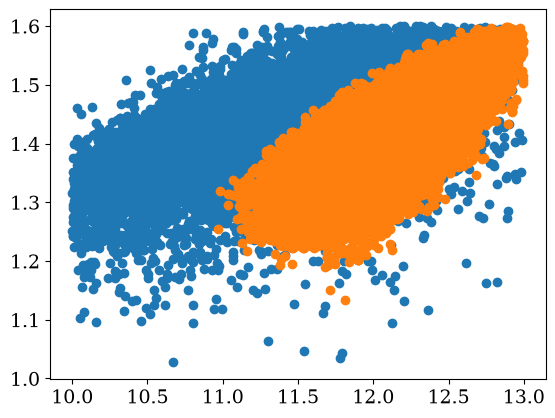

In [37]:
plt.scatter(mulinest[:,3], mulinest[:,2])
plt.scatter(pt_mcmc_full[:,3], pt_mcmc_full[:,2])

In [30]:
pt_mcmc_full.shape

(20000, 10)

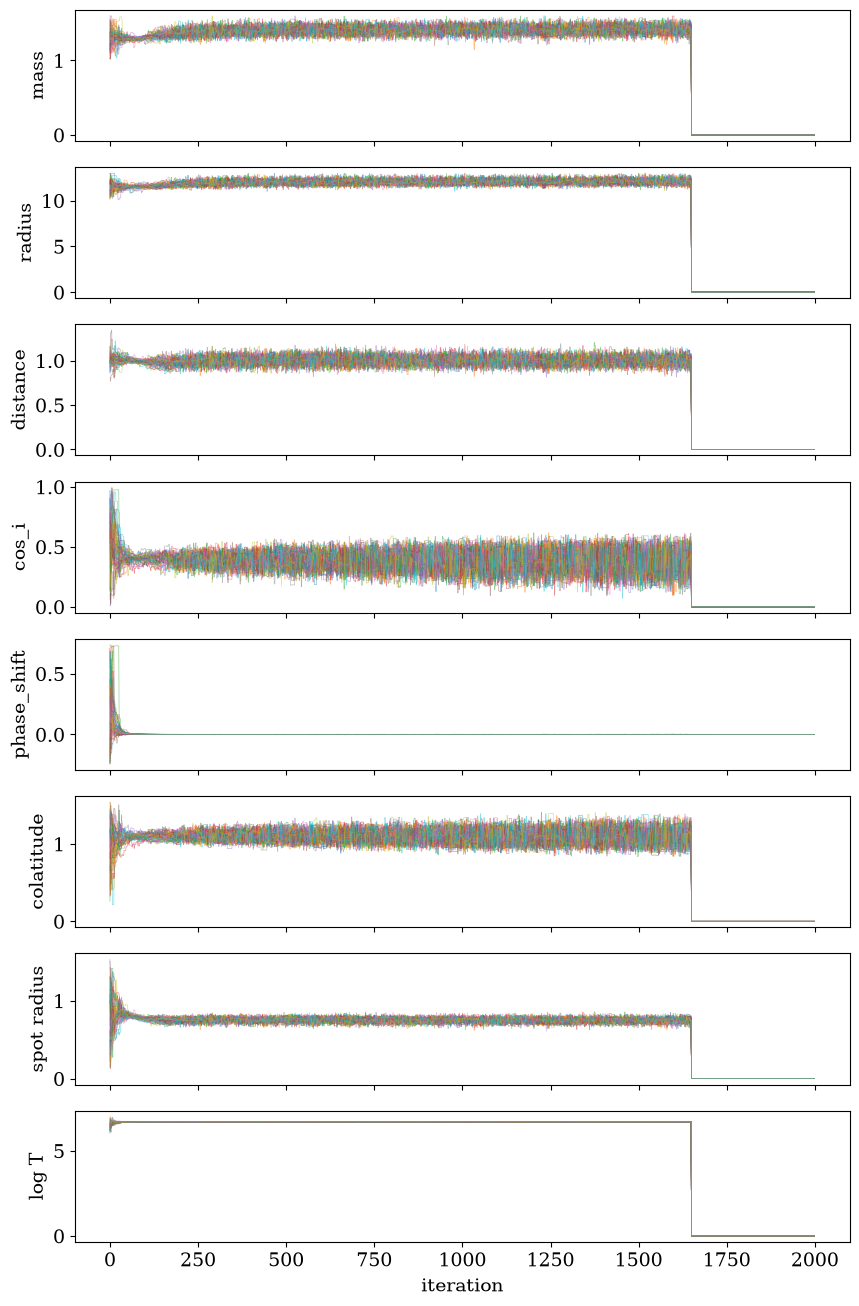

In [40]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load('../Outputs/ST_ptemcee_full_prior_ptemcee.npz')
chain = d['chain']        # shape (ntemps, nwalkers, nsteps, ndims) = (2, 1000, 2000, 8)
logl  = d['loglikelihood']  # shape (2, 1000, 2000)

cold = chain[0]           # cold chain (beta = 1): (walkers, iterations, parameters)

names = ['mass', 'radius', 'distance', 'cos_i',
         'phase_shift', 'colatitude', 'spot radius', 'log T']
fig, axes = plt.subplots(8, 1, figsize=(10, 16), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(cold[::20, :, k].T, lw=0.5, alpha=0.5)   # every 20th walker
    ax.set_ylabel(names[k])
axes[-1].set_xlabel('iteration')
plt.show()